In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Circuito RC
- Seja o circuito com um resistor ,um capacitor e corrente no sentindo horário.
- Com a lei de kirchhoff para tensão , obtem-se o modelo no tempo. Com a EDO linear e coef constante.

$$v(t) = R \cdot i(t) + \frac{1}{C} \int_{0}^{t} i(\tau)\, d\tau, \quad i(0) = 0$$

## Modelo

### Fonte de Tensão
- Fonte senoidal $v(t) = 5 \cdot sin(2\cdot \pi \cdot 60 \cdot t)$
- sendo a derivada:
$$
\frac{dv}{dt} = 5(2\pi60)cos(2\pi60t)
$$

## Modelo do EDO

$$
\frac{di}{dt} = \frac{1}{R} \cdot \frac{dv}{dt}-\frac{i}{C} 
$$

- Aplicando a fonte senoidal, tem-se

$$\boxed{
\frac{di}{dt}=
\frac{600\pi}{R}\cos(120\pi t)
-\frac{i}{RC}
}$$

- E admitimos a condição inicial de $i(0)= 0$



## Malhas
- Subdivisões de um domínio contínuo

## Discretização(Euler Explícito)
- Introduzir uma malha no tempo $N_{t+1}$ com ponto $t_n$
- Nos pontos da malha $t_n$, então introduzimos $u^n$ como a aproximação numérica de $u(t_n)$
- Assumimos uma diferencial valida nos pontos das malhas 
- Derivadas aproximadas por diferenças finitas
- Formulação computacional 
    - valores de $u^n$ baseado em previsões computacionais com valores $u^i$, i < n. 

## Discretização do Domínio
- Sendo o tempo uma variável contínuo , logo $t\in[0,T]$. Com representante computacional.

$$
0=t_0<t_1<t_2<\cdots<t_{N_t}=T
$$

- Admitindo malha uniforme:

$$\Delta t = \frac{T}{N_t} \rightarrow t_n = n\Delta t$$

![Foto do perfil](/home/theianreis/project/problem/python/img/malha_uniforme_tempo_circuito_RC.png)

- A corrente existe para todos os instantes no intervalo, mas a solução numérica será calculada no pontos da malha:

$$i^0,i^1,i^2,\ldots,i^{N_t}$$

- sendo: $
i^n\approx i(t_n)
$
- Portanto, $(i^n)$ é a aproximação numérica da corrente no instante $(t_n)$

## Satisfazer a equação nos pontos discretos:
- a EDO deve ser satisfeita continuamente:
$$
\frac{di}{dt}=f(t,i)
$$

- Para nosso circuito:
$$
f(t,i)=\frac{600\pi}{R}\cos(120\pi t)-\frac{i}{RC}
$$

- Na discretização, exigimos que a equação seja satisfeita aproximadamente nos pontos da malha.

No instante $(t_n)$:
$$
\boxed{
\left.\frac{di}{dt}\right|_{t_n}
=
\frac{600\pi}{R}\cos(120\pi t_n)
-\frac{i(t_n)}{RC}
}
$$

## Derivadas por diferenças finitas
$$
\frac{di}{dt}(t_n)=
\lim_{\Delta t\to0}
\frac{i(t_n+\Delta t)-i(t_n)}{\Delta t} \rightarrow \left.\frac{di}{dt}\right|_{t_n}
\approx
\frac{i^{n+1}-i^n}{\Delta t}
$$

- Aplicando na EDO, tem-se:

$$
\frac{i^{n+1}-i^n}{\Delta t}
=
\frac{600\pi}{R}\cos(120\pi t_n)
-\frac{i^n}{RC}
$$


## Construção da fórmula recursiva 
- Nosso objetivo é calcular a corrente futura \(i^{n+1}\) a partir da corrente conhecida \(i^n\).

$$
i^{n+1}-i^n=
\Delta t\left[
\frac{600\pi}{R}\cos(120\pi t_n)-\frac{i^n}{RC}
\right]

\rightarrow 
i^{n+1}=i^n+
\Delta t\left[
\frac{600\pi}{R}\cos(120\pi t_n)
-\frac{i^n}{RC}
\right]
$$

- Sendo está a equação de diferença do circuito RC pelo método de Forward Euler.
- Assim o algoritmo vai depender de 3 informações:
    - instante atual $t_n$
    - corrente atual $i^n$
    - passo temporal $\Delta t$

In [4]:
## Parâmetros
R = 1000.0
C = 1e-6
f = 60.0
V0 = 5.0

T = 0.05
dt = 1e-4
Nt = round(T / dt)

In [5]:
## malha
t = np.linspace(0, T, Nt + 1)

In [6]:
## Discretização
i = np.zeros(Nt+1)
i[0]=0.0

for n in range(Nt):
    dv_dt = V0 * 2 * np.pi * f * np.cos(2 * np.pi * f * t[n])
    di_dt = dv_dt / R - i[n] / (R * C)
    i[n + 1] = i[n] + dt * di_dt

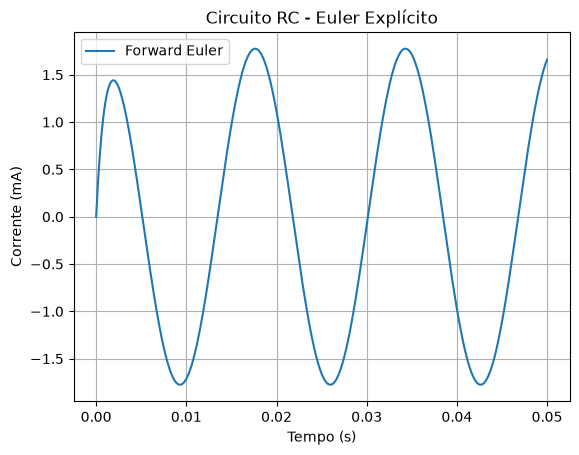

In [7]:
## Plotagem
plt.plot(t, i * 1000, label="Forward Euler")
plt.xlabel("Tempo (s)")
plt.ylabel("Corrente (mA)")
plt.title("Circuito RC - Euler Explícito")
plt.grid(True)
plt.legend()
plt.show()